In [2]:
!pip install ucimlrepo


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [3]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
ionosphere = fetch_ucirepo(id=52) 
  
# data (as pandas dataframes) 
X = ionosphere.data.features 
y = ionosphere.data.targets 
  
# metadata 
print(ionosphere.metadata) 
  
# variable information 
print(ionosphere.variables) 


{'uci_id': 52, 'name': 'Ionosphere', 'repository_url': 'https://archive.ics.uci.edu/dataset/52/ionosphere', 'data_url': 'https://archive.ics.uci.edu/static/public/52/data.csv', 'abstract': 'Classification of radar returns from the ionosphere', 'area': 'Physics and Chemistry', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 351, 'num_features': 34, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['Class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1989, 'last_updated': 'Sun Jan 01 1989', 'dataset_doi': '10.24432/C5W01B', 'creators': ['V. Sigillito', 'S. Wing', 'L. Hutton', 'K. Baker'], 'intro_paper': None, 'additional_info': {'summary': 'This radar data was collected by a system in Goose Bay, Labrador.  This system consists of a phased array of 16 high-frequency antennas with a total transmitted power on the order of 6.4 kilowatts.  See the paper for more details.  

In [4]:
y_bipolar = y['Class'].map({'g': 1, 'b': -1})

print(y_bipolar.value_counts())

Class
 1    225
-1    126
Name: count, dtype: int64


In [5]:
print("Total de valores ausentes:", X.isnull().sum().sum())

colunas_constantes = [col for col in X.columns if X[col].nunique() <= 1]
print("Atributos constantes:", colunas_constantes)

Total de valores ausentes: 0
Atributos constantes: ['Attribute2']


In [7]:
X_limpo = X.drop(columns=colunas_constantes)

print(X_limpo.shape)

(351, 33)


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X_limpo, y_bipolar, test_size=0.2, random_state=42, stratify=y_bipolar
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

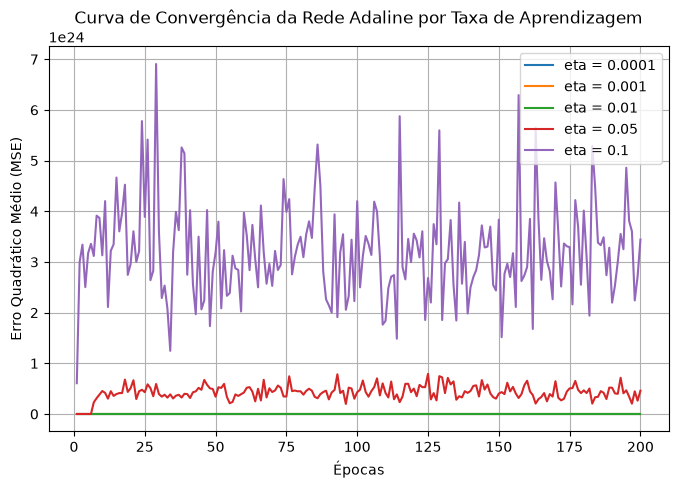

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import mean_squared_error

plt.rcParams["figure.figsize"] = (8, 5)

taxas_aprendizagem = [1e-4, 1e-3, 1e-2, 5e-2, 1e-1]
n_epochs = 200
classes = np.array([-1, 1])

for eta in taxas_aprendizagem:
    adaline_sklearn = SGDClassifier(
        loss='squared_error',
        eta0=eta,
        learning_rate='constant',
        penalty=None,
        random_state=42
    )
    
    cost_ = []
    
    for _ in range(n_epochs):
        idx = np.random.RandomState(42).permutation(len(X_train))
        adaline_sklearn.partial_fit(X_train[idx], y_train.values[idx], classes=classes)
        u = adaline_sklearn.decision_function(X_train)
        cost_.append(mean_squared_error(y_train, u))
    
    plt.plot(range(1, n_epochs + 1), cost_, label=f'eta = {eta}')

plt.xlabel('Épocas')
plt.ylabel('Erro Quadrático Médio (MSE)')
plt.title('Curva de Convergência da Rede Adaline por Taxa de Aprendizagem')
plt.legend()
plt.grid(True)
plt.show()

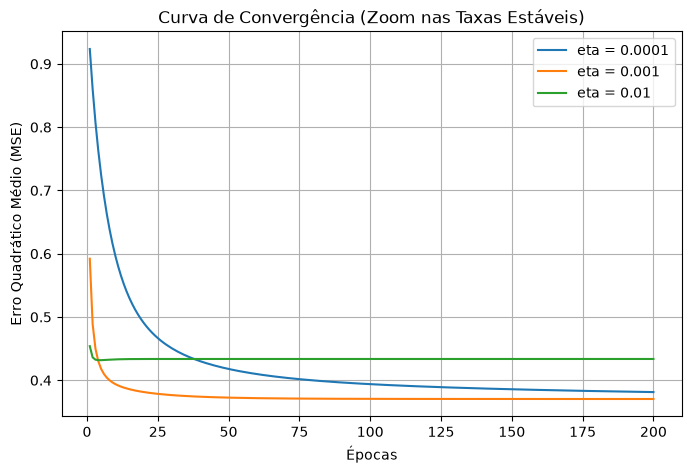

In [11]:
taxas_estaveis = [1e-4, 1e-3, 1e-2]
n_epochs = 200
classes = np.array([-1, 1])

plt.figure()

for eta in taxas_estaveis:
    adaline_sklearn = SGDClassifier(
        loss='squared_error',
        eta0=eta,
        learning_rate='constant',
        penalty=None,
        random_state=42
    )
    
    cost_ = []
    
    for _ in range(n_epochs):
        idx = np.random.RandomState(42).permutation(len(X_train))
        adaline_sklearn.partial_fit(X_train[idx], y_train.values[idx], classes=classes)
        u = adaline_sklearn.decision_function(X_train)
        cost_.append(mean_squared_error(y_train, u))
    
    plt.plot(range(1, n_epochs + 1), cost_, label=f'eta = {eta}')

plt.xlabel('Épocas')
plt.ylabel('Erro Quadrático Médio (MSE)')
plt.title('Curva de Convergência (Zoom nas Taxas Estáveis)')
plt.legend()
plt.grid(True)
plt.show()

In [12]:
adaline_sklearn = SGDClassifier(
    loss='squared_error',
    eta0=0.001,
    learning_rate='constant',
    max_iter=200,
    tol=None,
    shuffle=True,
    random_state=42
)

adaline_sklearn.fit(X_train, y_train)
y_pred_sklearn = adaline_sklearn.predict(X_test)

In [13]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred_sklearn))

print(f"Acurácia : {accuracy_score(y_test, y_pred_sklearn):.4f}")
print(f"Precisão : {precision_score(y_test, y_pred_sklearn):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_sklearn):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred_sklearn):.4f}")

Matriz de Confusão:
[[19  6]
 [ 0 46]]
Acurácia : 0.9155
Precisão : 0.8846
Recall   : 1.0000
F1-Score : 0.9388
